# OCSMM-SHAP 
## Student grades at school level - Synthetic dataset

In [1]:
import pandas as pd
import numpy as np

# Configuration
n_schools = 30
n_students_per_school = 100  # 100 students per school
subjects = ["Math", "History", "English", "Geography", "Physics",
            "Art", "Music", "PE", "Chemistry", "Biology"]
n_subjects = 10
np.random.seed(42)
dataset = []

In [2]:
for school_id in range(n_schools):
    school_grades = np.zeros((n_students_per_school, n_subjects))
    
    # Normal schools
    base_params = np.array([
        [75, 5],   # Math
        [80, 4],   # History
        [70, 8],   # English
        [72, 6],   # Geography
        [68, 7],   # Physics
        [85, 3],   # Art
        [88, 2],   # Music
        [90, 1],   # PE
        [78, 5],   # Chemistry
        [77, 5]    # Biology
    ])
    # Add this after generating the main 29 groups

for school_id in range(n_schools):  # Only 29 normal schools
    school_grades = np.zeros((n_students_per_school, n_subjects))
    for subj_idx in range(n_subjects):
        mean, std = base_params[subj_idx]
        grades = np.random.normal(mean, std, n_students_per_school)
        school_grades[:, subj_idx] = np.clip(grades, 0, 100).astype(int)
    dataset.append(school_grades)



In [3]:
# Anomaly 1: Art grades (column 5) much lower
dataset[29][:, 5] = np.random.randint(60, 70, size=n_students_per_school)

# Anomaly 2: Physics grades (column 1) higher with outliers
physics_grades = np.random.normal(90, 10, n_students_per_school)
dataset[29][:, 4] = np.clip(physics_grades, 0, 100).astype(int)

In [4]:
len(dataset)

30

In [5]:
dataset

[array([[ 77.,  74.,  72.,  67.,  56.,  87.,  89.,  89.,  82.,  78.],
        [ 74.,  78.,  74.,  68.,  63.,  90.,  86.,  91.,  75.,  75.],
        [ 78.,  78.,  78.,  76.,  68.,  80.,  89.,  89.,  78.,  77.],
        [ 82.,  76.,  78.,  75.,  68.,  86.,  90.,  88.,  75.,  83.],
        [ 73.,  79.,  58.,  71.,  64.,  83.,  88.,  88.,  75.,  77.],
        [ 73.,  81.,  62.,  72.,  72.,  83.,  91.,  90.,  76.,  77.],
        [ 82.,  87.,  74.,  79.,  60.,  83.,  86.,  88.,  79.,  70.],
        [ 78.,  80.,  74.,  68.,  67.,  82.,  85.,  91.,  75.,  80.],
        [ 72.,  81.,  74.,  75.,  68.,  85.,  84.,  87.,  84.,  80.],
        [ 77.,  79., 100.,  70.,  71.,  82.,  90.,  91.,  73.,  87.],
        [ 72.,  72.,  74.,  70.,  72.,  85.,  89.,  90.,  77.,  75.],
        [ 72.,  79.,  79.,  78.,  60.,  84.,  87.,  89.,  75.,  78.],
        [ 76.,  80.,  77.,  76.,  57.,  84.,  88.,  89.,  85.,  78.],
        [ 65.,  89.,  75.,  76.,  76.,  82.,  85.,  90.,  78.,  84.],
        [ 66.,  79.,

In [6]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier

In [7]:
classifier = OneClassSMMClassifier(nu=0.1)

In [8]:
classifier.fit(dataset)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [9]:
decision, y_pred = classifier.predict(dataset)

Calculating kappa.

calculating rho.

0.6526206600342942


In [10]:
decision

array([ 0.06785267,  0.07596476,  0.07304838,  0.06992633,  0.06982844,
        0.06924313,  0.06673834,  0.07154619,  0.07021402,  0.06735192,
        0.07127157,  0.06434809,  0.06872209,  0.06755153,  0.06924051,
        0.0722982 ,  0.07356246,  0.0643478 ,  0.07162198,  0.06795253,
        0.0664718 ,  0.0698884 ,  0.06434133,  0.07284557,  0.06649042,
        0.07090959,  0.07038335,  0.07264881,  0.06912656, -0.19303723])

In [11]:
y_pred = np.sign(decision)

In [12]:
y_pred

array([ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1., -1.])

In [13]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[29]

In [14]:
from src.explanation_algorithms.OCSMMSHAP import OCSMMSHAP
ocsmm_shap = OCSMMSHAP(X=dataset, classifier=classifier, decision=decision, num_cpus=150)
ocsmm_shap.fit_ocsmmshap(X=dataset, num_coalitions=2**10)

Calculating projections: 100%|██████████| 1023/1023 [00:28<00:00, 36.06it/s]


In [15]:
shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [16]:
shapley_values = 100* shapley_values

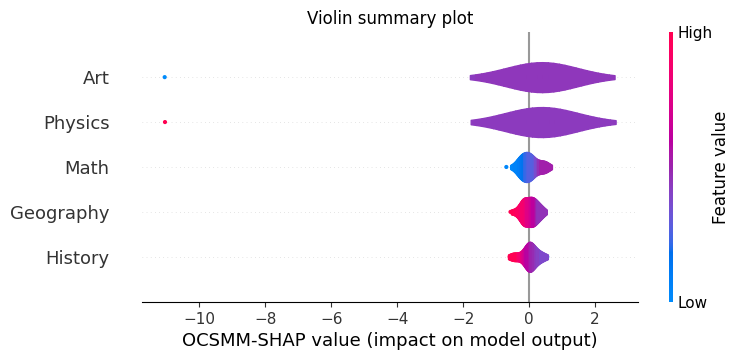

In [17]:
from src.utils.visualisation.deterministic_values import global_bar_plot_ocsmm, local_bar_plot_ocsmm, summary_plot_ocsmm
summary_plot_ocsmm(shapley_values.T.numpy(), feature_names=subjects, datasets=dataset)

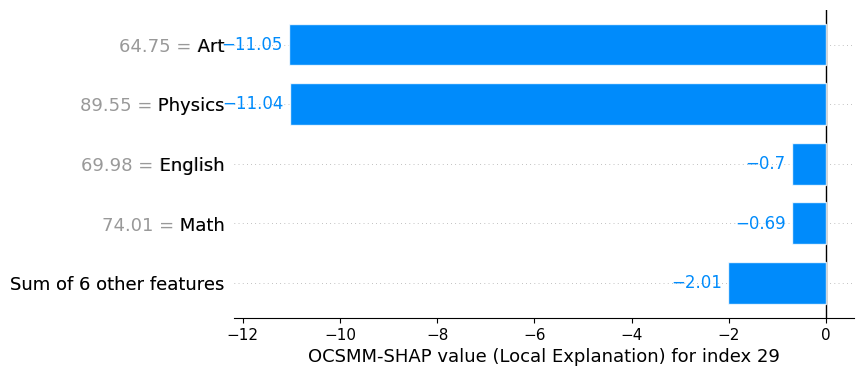

In [18]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 29, feature_names=subjects, datasets=dataset)

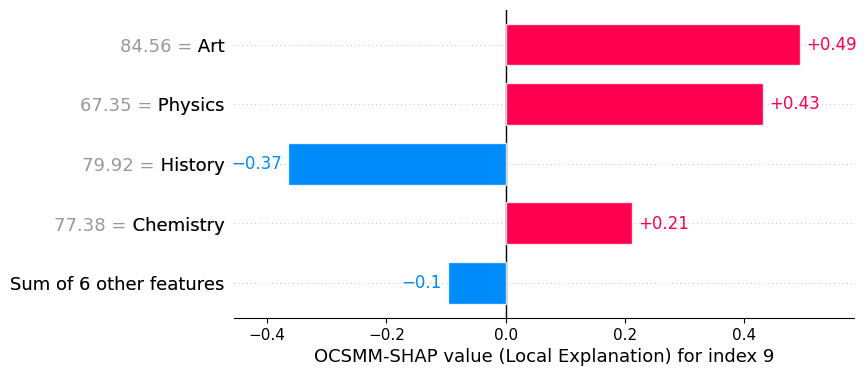

In [19]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 9, feature_names=subjects, datasets=dataset)

/tmp/ipykernel_2141329/1803132644.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)


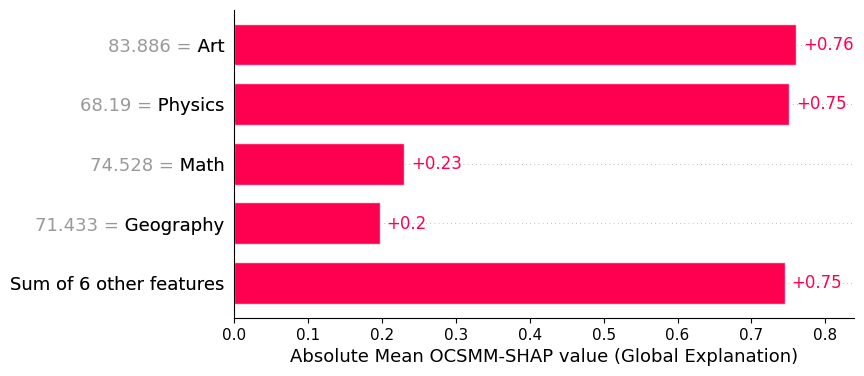

In [20]:
import numpy as np
# global importance measure
mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=subjects, datasets=dataset)

In [ ]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import OCSMMSHAPIQ, display_network_plot
shapiq = OCSMMSHAPIQ(n=10, max_order=2, random_state=42)
interactions_per_group = shapiq.explain_single_group(
    group_data=dataset[29],
    X=dataset,  
    model=classifier,
    regularization=1e-6,
    budget=2**10)

  0%|          | 0/1024 [00:00<?, ?it/s]

100%|██████████| 1024/1024 [00:09<00:00, 102.66it/s]


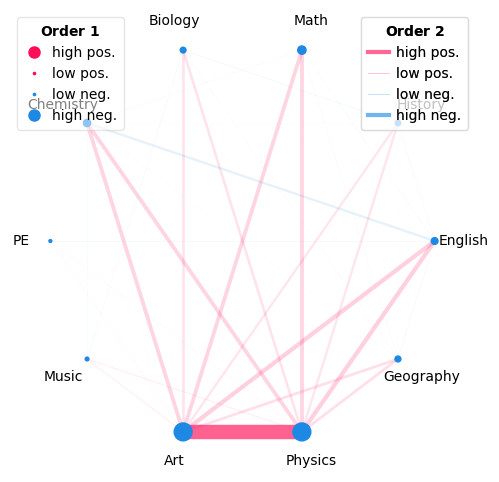

In [22]:
interactions_per_group.plot_network(feature_names=subjects, show=True)

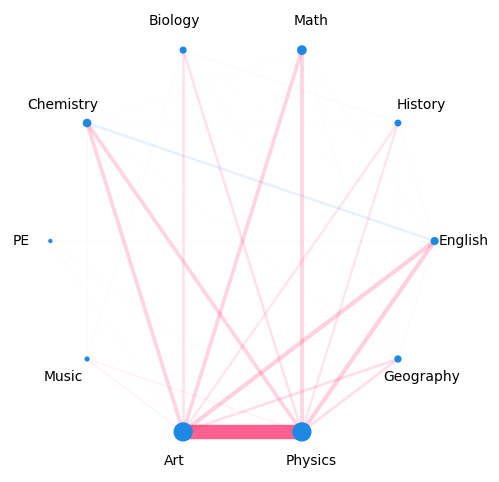

In [23]:
display_network_plot(interactions_per_group, feature_names=subjects)

100%|██████████| 1024/1024 [00:03<00:00, 302.80it/s]


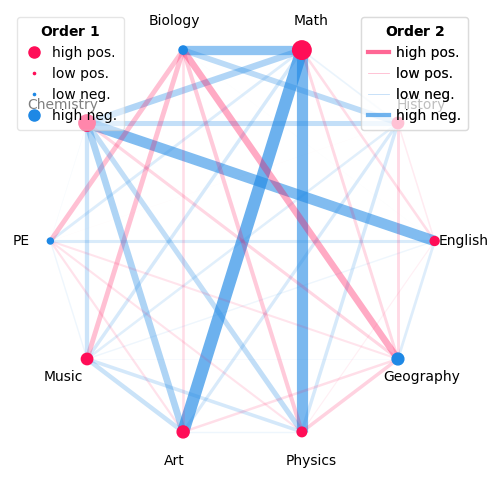

In [24]:
shapiq = OCSMMSHAPIQ(n=10, max_order=2, random_state=42)
interactions_per_group = shapiq.explain_single_group(
    group_data=dataset[7],
    X=dataset,  
    model=classifier,
    regularization=1e-6,
    budget=2**10)
interactions_per_group.plot_network(feature_names=subjects, show=True)

In [26]:
interactions_per_group.dict_values

{(): 0.7133765978406718,
 (0,): 0.01620698296554222,
 (1,): 0.00621277923853332,
 (2,): 0.0037623040179966794,
 (3,): -0.006628726801885436,
 (4,): 0.004344985776516238,
 (5,): 0.006802235167409814,
 (6,): 0.006143172248695634,
 (7,): -0.001736418543086626,
 (8,): 0.012625398166788428,
 (9,): -0.0032695251122428237,
 (0, 1): -0.0008856374561398922,
 (0, 2): 0.0013899793320402626,
 (0, 3): 0.0015543246626341402,
 (0, 4): -0.005922513474505334,
 (0, 5): -0.00651950026672809,
 (0, 6): -0.0018196281799334499,
 (0, 7): -0.0015048230602392023,
 (0, 8): -0.003477667495535575,
 (0, 9): -0.004921733317905285,
 (1, 2): 0.0008150828138799306,
 (1, 3): 0.0015314289665825946,
 (1, 4): -0.0018258805717406993,
 (1, 5): -0.0016827168175533457,
 (1, 6): -0.001321006451296557,
 (1, 7): 0.0001778384067898544,
 (1, 8): -0.0026906206118586435,
 (1, 9): -0.00300845394859807,
 (2, 3): -0.0014561716598426506,
 (2, 4): 0.0006171957694544421,
 (2, 5): 8.952615919984041e-05,
 (2, 6): -0.0007398764235900535,
 (2,